In [1]:
!apt install -y postgresql postgresql-contrib -qq
!pip install psycopg2-binary pyngrok


The following additional packages will be installed:
  libcommon-sense-perl libjson-perl libjson-xs-perl libtypes-serialiser-perl
  logrotate netbase postgresql-14 postgresql-client-14
  postgresql-client-common postgresql-common ssl-cert sysstat
Suggested packages:
  bsd-mailx | mailx postgresql-doc postgresql-doc-14 isag
The following NEW packages will be installed:
  libcommon-sense-perl libjson-perl libjson-xs-perl libtypes-serialiser-perl
  logrotate netbase postgresql postgresql-14 postgresql-client-14
  postgresql-client-common postgresql-common postgresql-contrib ssl-cert
  sysstat
0 upgraded, 14 newly installed, 0 to remove and 35 not upgraded.
Need to get 18.4 MB of archives.
After this operation, 52.0 MB of additional disk space will be used.
Preconfiguring packages ...
Selecting previously unselected package logrotate.
(Reading database ... 126284 files and directories currently installed.)
Preparing to unpack .../00-logrotate_3.19.0-1ubuntu1.1_amd64.deb ...
Unpacking logro

In [2]:
from pyngrok import ngrok

# 设置你的 ngrok authtoken，从这里获取：https://dashboard.ngrok.com/get-started/your-authtoken
ngrok.set_auth_token("你的token")

# 然后创建隧道
tunnel = ngrok.connect(5432, "tcp")

In [3]:

# 2. 启动 PostgreSQL
print("🚀 启动 PostgreSQL...")
!sudo service postgresql start
!sudo -u postgres psql -c "ALTER USER postgres PASSWORD 'password123';"

# 3. 创建数据库和表格
print("🗄️ 创建数据库和表格...")

import psycopg2
from pyngrok import ngrok

# 连接数据库并创建演示数据
conn = psycopg2.connect(
    host="localhost",
    user="postgres",
    password="password123",
    database="postgres"
)
conn.autocommit = True
cursor = conn.cursor()

# 创建数据库
cursor.execute("DROP DATABASE IF EXISTS demo_db;")
cursor.execute("CREATE DATABASE demo_db;")
print("✅ 创建数据库: demo_db")

# 切换到新数据库
cursor.close()
conn.close()

conn = psycopg2.connect(
    host="localhost",
    user="postgres",
    password="password123",
    database="demo_db"
)
conn.autocommit = True
cursor = conn.cursor()

# 创建用户表
cursor.execute("""
    CREATE TABLE users (
        id SERIAL PRIMARY KEY,
        name VARCHAR(50),
        email VARCHAR(100),
        age INTEGER
    );
""")

# 创建产品表
cursor.execute("""
    CREATE TABLE products (
        id SERIAL PRIMARY KEY,
        name VARCHAR(100),
        price DECIMAL(10,2),
        category VARCHAR(50)
    );
""")

# 插入用户数据
users_data = [
    ('张三', 'zhang@test.com', 25),
    ('李四', 'li@test.com', 30),
    ('王五', 'wang@test.com', 28)
]

for user in users_data:
    cursor.execute("INSERT INTO users (name, email, age) VALUES (%s, %s, %s);", user)

# 插入产品数据
products_data = [
    ('笔记本电脑', 5999.99, '电子产品'),
    ('无线鼠标', 199.99, '电子产品'),
    ('咖啡杯', 39.99, '生活用品'),
    ('书籍', 29.99, '文具')
]

for product in products_data:
    cursor.execute("INSERT INTO products (name, price, category) VALUES (%s, %s, %s);", product)

print("✅ 创建表格并插入数据完成")

# 显示数据
print("\n📊 用户表数据:")
cursor.execute("SELECT * FROM users;")
for row in cursor.fetchall():
    print(f"ID:{row[0]} 姓名:{row[1]} 邮箱:{row[2]} 年龄:{row[3]}")

print("\n📊 产品表数据:")
cursor.execute("SELECT * FROM products;")
for row in cursor.fetchall():
    print(f"ID:{row[0]} 产品:{row[1]} 价格:{row[2]} 分类:{row[3]}")

cursor.close()
conn.close()

# 4. 设置 ngrok 内网穿透
print("\n🌐 设置 ngrok 内网穿透...")

try:
    # 创建隧道
    tunnel = ngrok.connect(5432, "tcp")
    public_url = tunnel.public_url

    # 解析地址
    host_port = public_url.replace('tcp://', '')
    host, port = host_port.split(':')

    print("🎉 ngrok 隧道创建成功!")
    print(f"本地地址: localhost:5432")
    print(f"公网地址: {host}:{port}")

    # 5. 测试远程连接
    print("\n🔄 测试远程连接...")
    test_conn = psycopg2.connect(
        host=host,
        port=port,
        user="postgres",
        password="password123",
        database="demo_db"
    )

    test_cursor = test_conn.cursor()
    test_cursor.execute("SELECT COUNT(*) FROM users;")
    user_count = test_cursor.fetchone()[0]

    test_cursor.execute("SELECT COUNT(*) FROM products;")
    product_count = test_cursor.fetchone()[0]

    print(f"✅ 远程连接成功! 用户:{user_count}个, 产品:{product_count}个")

    test_cursor.close()
    test_conn.close()

    # 连接信息
    print("\n" + "="*50)
    print("📋 连接信息:")
    print(f"主机: {host}")
    print(f"端口: {port}")
    print(f"用户名: postgres")
    print(f"密码: password123")
    print(f"数据库: demo_db")
    print(f"\n命令行连接:")
    print(f"psql -h {host} -p {port} -U postgres -d demo_db")
    print("\n⚠️ 保持此会话运行以维持连接!")

except Exception as e:
    print(f"❌ ngrok 设置失败: {e}")
    print("💡 如需稳定连接，请访问 https://dashboard.ngrok.com/ 注册获取 authtoken")

🚀 启动 PostgreSQL...
 * Starting PostgreSQL 14 database server
   ...done.
ALTER ROLE
🗄️ 创建数据库和表格...
✅ 创建数据库: demo_db
✅ 创建表格并插入数据完成

📊 用户表数据:
ID:1 姓名:张三 邮箱:zhang@test.com 年龄:25
ID:2 姓名:李四 邮箱:li@test.com 年龄:30
ID:3 姓名:王五 邮箱:wang@test.com 年龄:28

📊 产品表数据:
ID:1 产品:笔记本电脑 价格:5999.99 分类:电子产品
ID:2 产品:无线鼠标 价格:199.99 分类:电子产品
ID:3 产品:咖啡杯 价格:39.99 分类:生活用品
ID:4 产品:书籍 价格:29.99 分类:文具

🌐 设置 ngrok 内网穿透...
🎉 ngrok 隧道创建成功!
本地地址: localhost:5432
公网地址: 4.tcp.ngrok.io:19411

🔄 测试远程连接...
✅ 远程连接成功! 用户:3个, 产品:4个

📋 连接信息:
主机: 4.tcp.ngrok.io
端口: 19411
用户名: postgres
密码: password123
数据库: demo_db

命令行连接:
psql -h 4.tcp.ngrok.io -p 19411 -U postgres -d demo_db

⚠️ 保持此会话运行以维持连接!


### ✅查看Endpoints https://dashboard.ngrok.com/endpoints
#### 如图⬇️

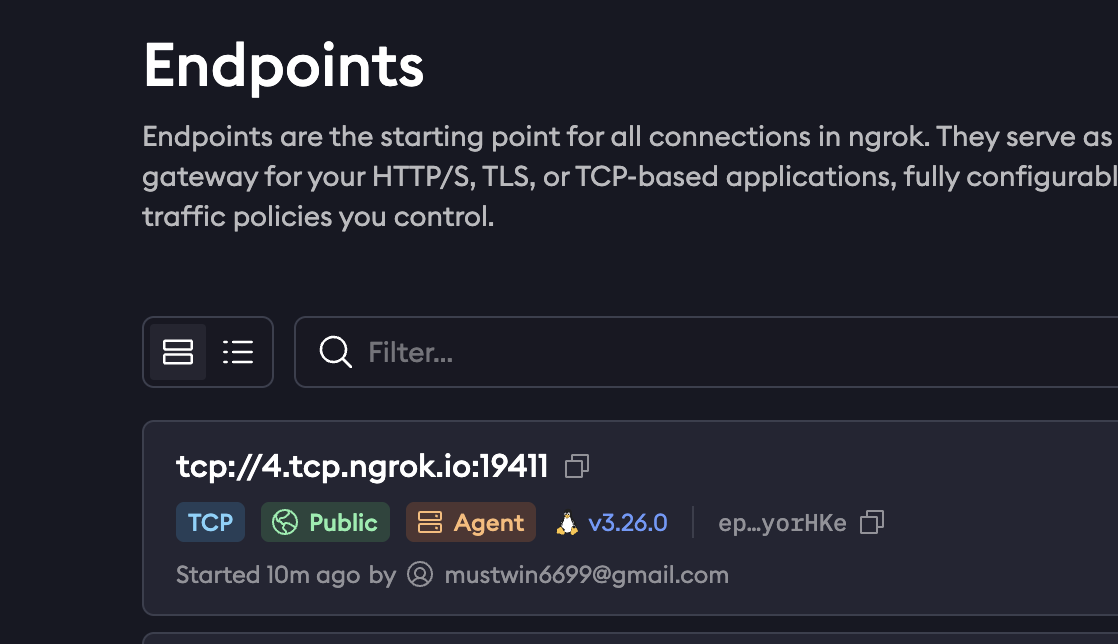